# Exercice 1  : Reconnaissance de chiffres manuscrits(MNIST)

In [2]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Flatten
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt
import numpy as np

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


Réponses aux questions :



*   TensorFlow vs Keras : TensorFlow est le moteur de calcul (tenseurs, CPU/GPU). Keras est l’interface simple pour construire des réseaux au-dessus de TensorFlow.
*   Flatten : transforme l’image 28×28 en un vecteur de 784 valeurs, car une couche Dense attend un vecteur.


*  Version installée : elle s’affiche avec le print. 2.21.0
.
*   Sequential : empile les couches l’une après l’autre.


*   Dense : couche où chaque neurone est relié à tous les neurones de la couche précédente.











In [3]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

x_train = x_train / 255.0
x_test = x_test / 255.0

print("x_train shape:", x_train.shape)   # (60000, 28, 28)
print("y_train shape:", y_train.shape)   # (60000,)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
x_train shape: (60000, 28, 28)
y_train shape: (60000,)


Réponses :


*   Pourquoi normaliser ? Les pixels vont de 0 à 255. En les ramenant entre 0 et 1, l’apprentissage est plus stable et converge plus vite.
* Taille d’une image : 28×28 pixels, en niveaux de gris. Type d’origine : uint8 (entiers de 0 à 255). Après division par 255.0, ce sont des float64.  

*  Exemples d’entraînement : 60 000 (et 10 000 pour le test).



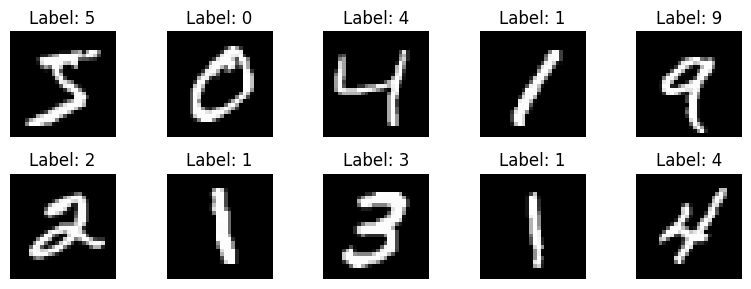

In [4]:
plt.figure(figsize=(8, 3))
for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')
plt.tight_layout()
plt.show()



Réponses :

**Modifier le nombre d’images** : changer range(10) et la grille plt.subplot(lignes, colonnes, i+1).
**cmap='gray'** : affiche l’image en niveaux de gris (sinon matplotlib applique des couleurs par défaut).
**Utilité** : vérifier que les données sont correctes avant de perdre du temps à entraîner.

In [5]:
model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

Réponses :

**Nombre de paramètres **: 101 770.
Couche Dense(128) : 784 × 128 + 128 = 100 480
Couche Dense(10) : 128 × 10 + 10 = 1 290
Vérifiez avec model.summary().
**Activation de sortie **: softmax, car elle transforme les 10 sorties en probabilités dont la somme vaut 1. Le chiffre prédit est celui de plus forte probabilité.
**ReLU vs Softmax** : ReLU (max(0, x)) s’utilise dans les couches cachées et introduit la non-linéarité. Softmax s’utilise en sortie pour une classification multiclasse.

In [7]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

Réponses :

**Optimiseur** : l’algorithme qui ajuste les poids pour réduire la perte (Adam, SGD, RMSprop).

**Pourquoi une fonction de perte ?** Elle mesure l’erreur du modèle. Sans elle, le modèle ne saurait pas dans quel sens corriger ses poids.

**Si on la change** : une perte inadaptée (par exemple MSE pour de la classification) donne un apprentissage moins efficace, ou une erreur si les formats ne correspondent pas.

**Mauvais optimiseur** : apprentissage très lent, instable, ou bloqué sur un mauvais résultat.

 **Loss vs metrics** : la loss est ce que le modèle minimise pendant l’entraînement. La métrique (accuracy) sert seulement à nous informer, elle n’influence pas l’apprentissage.

In [8]:
history = model.fit(
    x_train, y_train,
    epochs=5,
    batch_size=32,
    validation_data=(x_test, y_test)
)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.9276 - loss: 0.2539 - val_accuracy: 0.9587 - val_loss: 0.1386
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9673 - loss: 0.1099 - val_accuracy: 0.9636 - val_loss: 0.1180
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9766 - loss: 0.0763 - val_accuracy: 0.9719 - val_loss: 0.0900
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9824 - loss: 0.0576 - val_accuracy: 0.9729 - val_loss: 0.0836
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step - accuracy: 0.9865 - loss: 0.0453 - val_accuracy: 0.9792 - val_loss: 0.0702


Réponses :

Époque : un passage complet sur toutes les données d’entraînement.

Jeu de validation : mesurer pendant l’entraînement la performance sur des données non apprises, pour détecter le surapprentissage.

50 époques : la précision d’entraînement continue de monter, mais la validation stagne ou baisse, ce qui est du surapprentissage. Cela prend aussi plus de temps.

In [9]:
test_loss, test_acc = model.evaluate(x_test, y_test)
print(f"Test accuracy: {test_acc:.4f}")
print(f"Test loss: {test_loss:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9792 - loss: 0.0702
Test accuracy: 0.9792
Test loss: 0.0702


Réponses :

Précision finale : 0.9792

Test inférieur à l’entraînement : le modèle a appris sur les données d’entraînement et ne voit les données de test qu’une fois.

Si surapprentissage : ajouter du Dropout, réduire la taille du modèle, arrêter plus tôt (early stopping), ajouter des données (data augmentation), régulariser

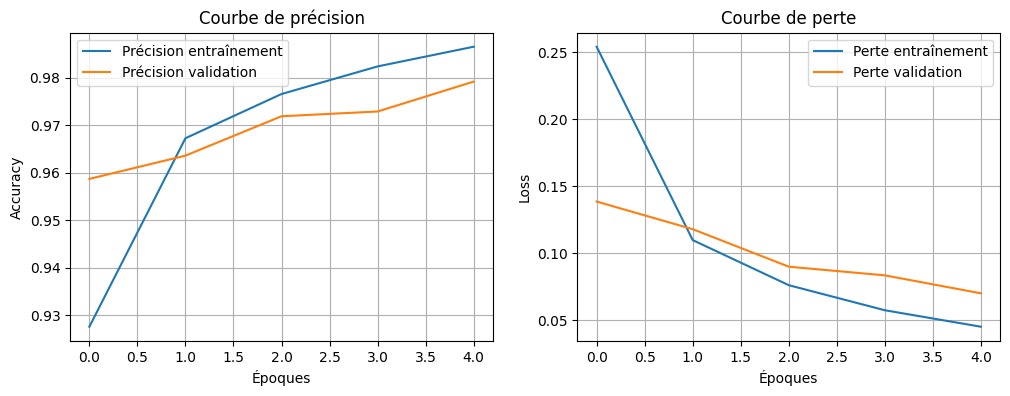

In [10]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Précision entraînement')
plt.plot(history.history['val_accuracy'], label='Précision validation')
plt.title('Courbe de précision')
plt.xlabel('Époques'); plt.ylabel('Accuracy')
plt.legend(); plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Perte entraînement')
plt.plot(history.history['val_loss'], label='Perte validation')
plt.title('Courbe de perte')
plt.xlabel('Époques'); plt.ylabel('Loss')
plt.legend(); plt.grid(True)

plt.show()

Réponses :

Que remarque-t-on ? En général, la précision augmente et la perte diminue, les courbes d’entraînement et de validation restent proches.

Détecter le surapprentissage : la précision d’entraînement continue de monter alors que celle de validation stagne ou baisse (et la perte de validation remonte).

Remèdes : Dropout, early stopping, moins de neurones, plus de données.

Si les courbes divergent : c’est un signe de surapprentissage, appliquez les remèdes ci-dessus.

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


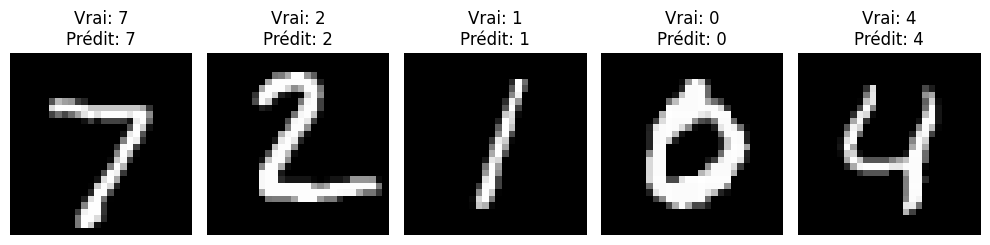

In [11]:
predictions = model.predict(x_test)

plt.figure(figsize=(10, 4))
for i in range(5):
    plt.subplot(1, 5, i+1)
    plt.imshow(x_test[i], cmap='gray')
    plt.title(f"Vrai: {y_test[i]}\nPrédit: {np.argmax(predictions[i])}")
    plt.axis('off')
plt.tight_layout()
plt.show()

Réponses :

Erreurs ? Souvent aucune sur 5 images. Pour en trouver, affichez davantage d’images (par exemple 20) ou cherchez celles où np.argmax(predictions[i]) != y_test[i].

Expliquer une erreur : écriture ambiguë, chiffres qui se ressemblent (4 et 9, 3 et 5, 7 et 1), image mal centrée.

Améliorer : un CNN, qui exploite la structure spatiale de l’image .

# EXERCICE 2 : Fashion-MNIST

In [12]:
import tensorflow as tf
from tensorflow.keras.datasets import fashion_mnist
import matplotlib.pyplot as plt
import seaborn as sns

tf.random.set_seed(42)   # reproductibilité

(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Dimensions du train set : (60000, 28, 28)
Dimensions du test set : (10000, 28, 28)


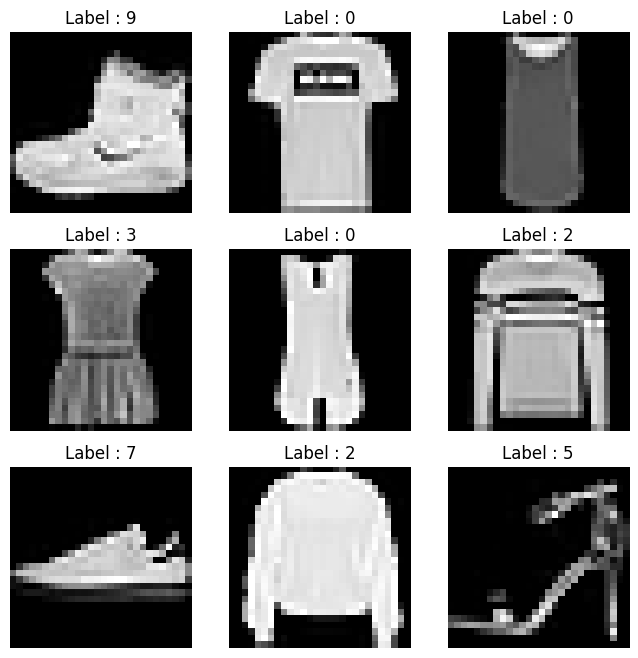

In [13]:
print("Dimensions du train set :", X_train.shape)   # (60000, 28, 28)
print("Dimensions du test set :", X_test.shape)     # (10000, 28, 28)

plt.figure(figsize=(8, 8))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f"Label : {y_train[i]}")
    plt.axis('off')
plt.show()

Réponse : les données sont des images de vêtements en niveaux de gris, de petite taille (28×28), avec 10 classes numérotées de 0 à 9. Leur faible résolution rend certaines classes difficiles à distinguer (chemise, T-shirt, pull).

In [14]:
from tensorflow.keras.utils import to_categorical

X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

Réponses :

Normalisation : même raison que l’exercice 1, convergence plus rapide et stable.

One-hot encoding : le label 3 devient [0,0,0,1,0,0,0,0,0,0]. Cela correspond à la sortie softmax (10 probabilités) et évite que le modèle croie qu’une classe 9 est « plus grande » qu’une classe 1 (il n’y a pas d’ordre entre les classes). C’est pourquoi on utilise categorical_crossentropy ici.

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.7817 - loss: 0.6232 - val_accuracy: 0.8436 - val_loss: 0.4342
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8478 - loss: 0.4247 - val_accuracy: 0.8549 - val_loss: 0.3960
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8614 - loss: 0.3820 - val_accuracy: 0.8587 - val_loss: 0.3800
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8685 - loss: 0.3585 - val_accuracy: 0.8652 - val_loss: 0.3599
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8763 - loss: 0.3389 - val_accuracy: 0.8662 - val_loss: 0.3597
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8808 - loss: 0.3245 - val_accuracy: 0.8698 - val_loss: 0.3506
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8846 - loss: 0.3136 - val_accuracy: 0.8758 - val_loss: 0.3368
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8881 - loss: 0.3054 - val_accuracy: 0

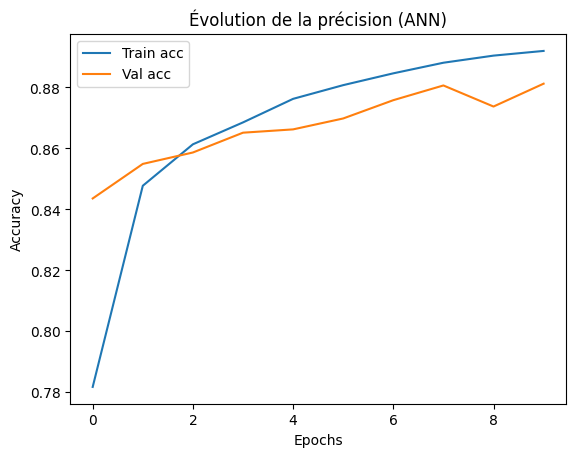

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8733 - loss: 0.3510
Précision sur le test set : 0.8733000159263611


In [15]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense, Dropout

model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])
model.summary()

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    X_train, y_train_cat,
    epochs=10,
    batch_size=128,
    validation_split=0.2
)

plt.plot(history.history['accuracy'], label='Train acc')
plt.plot(history.history['val_accuracy'], label='Val acc')
plt.legend()
plt.title('Évolution de la précision (ANN)')
plt.xlabel('Epochs'); plt.ylabel('Accuracy')
plt.show()

test_loss, test_acc = model.evaluate(X_test, y_test_cat)
print("Précision sur le test set :", test_acc)

Réponses :

Pourquoi ReLU ? Simple, rapide à calculer, et elle limite le problème du gradient qui disparaît, ce qui accélère l’apprentissage.

accuracy vs val_accuracy : accuracy est calculée sur les données d’entraînement, val_accuracy sur la partie mise de côté (20 % ici, via validation_split=0.2) que le modèle n’apprend pas.

50 époques : risque de surapprentissage, la précision d’entraînement monte mais celle de validation plafonne puis baisse.

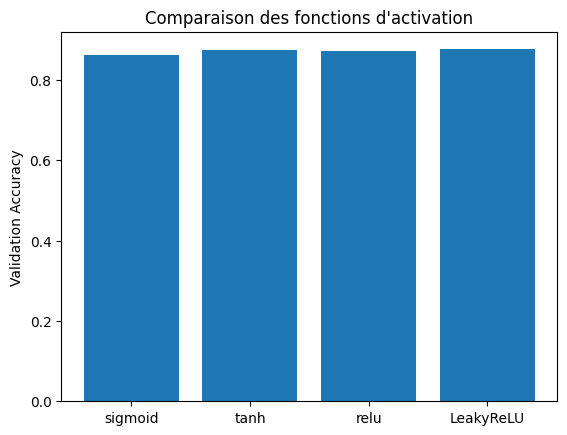

{'sigmoid': 0.8615833520889282, 'tanh': 0.8736666440963745, 'relu': 0.871833324432373, 'LeakyReLU': 0.8757500052452087}


In [16]:
from tensorflow.keras.layers import LeakyReLU

activations = ['sigmoid', 'tanh', 'relu']
results = {}

for act in activations:
    model_act = Sequential([
        Input(shape=(28, 28)),
        Flatten(),
        Dense(128, activation=act),
        Dense(64, activation=act),
        Dense(10, activation='softmax')
    ])
    model_act.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    h = model_act.fit(X_train, y_train_cat, epochs=5, batch_size=128,
                      validation_split=0.2, verbose=0)
    results[act] = h.history['val_accuracy'][-1]

# Leaky ReLU
model_leaky = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128),
    LeakyReLU(0.1),
    Dense(64),
    LeakyReLU(0.1),
    Dense(10, activation='softmax')
])
model_leaky.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
h = model_leaky.fit(X_train, y_train_cat, epochs=5, batch_size=128,
                    validation_split=0.2, verbose=0)
results['LeakyReLU'] = h.history['val_accuracy'][-1]

plt.bar(list(results.keys()), list(results.values()))
plt.title("Comparaison des fonctions d'activation")
plt.ylabel("Validation Accuracy")
plt.show()
print(results)

Réponses :

Meilleure fonction : regardez le graphique et print(results). En général, ReLU et LeakyReLU sont en tête (sigmoïde est souvent un peu derrière), mais les écarts sont petits, c’est à vous de lire vos propres résultats.

Pourquoi sigmoïde et tanh sont moins utilisées dans les couches cachées ? Elles saturent (leur courbe devient plate pour de grandes valeurs), donc le gradient devient presque nul et l’apprentissage est lent dans les réseaux profonds (vanishing gradient). Elles sont aussi plus coûteuses à calculer.

LeakyReLU : comme ReLU, mais laisse passer une petite pente (ici 0,1) pour les valeurs négatives au lieu de les mettre à 0. Cela évite les « neurones morts » (neurones qui ne s’activent plus jamais).

In [ ]:
from tensorflow.keras.layers import Conv2D, MaxPooling2D

X_train_cnn = X_train.reshape(-1, 28, 28, 1)
X_test_cnn = X_test.reshape(-1, 28, 28, 1)

cnn = Sequential([
    Input(shape=(28, 28, 1)),
    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(10, activation='softmax')
])
cnn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
cnn.summary()

history_cnn = cnn.fit(
    X_train_cnn, y_train_cat,
    epochs=10,
    batch_size=128,
    validation_split=0.2
)

test_loss, test_acc = cnn.evaluate(X_test_cnn, y_test_cat)
print("Précision CNN sur test set :", test_acc)

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 56s 142ms/step - accuracy: 0.7744 - loss: 0.6232 - val_accuracy: 0.8526 - val_loss: 0.4148
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 59s 157ms/step - accuracy: 0.8572 - loss: 0.3976 - val_accuracy: 0.8713 - val_loss: 0.3531
Epoch 3/10


Réponses :

ANN vs CNN : l’ANN aplatit l’image et perd la notion de position des pixels voisins. Le CNN utilise des filtres qui parcourent l’image et détectent des motifs locaux (bords, formes).

Pourquoi le CNN est meilleur ? Il exploite la structure spatiale, partage ses filtres sur toute l’image (moins de paramètres) et reconnaît un motif où qu’il se trouve.

Pooling : réduit la taille des cartes de caractéristiques (ici ÷2), donc moins de calculs, et rend le modèle plus robuste à de petits décalages.

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np

y_pred = np.argmax(cnn.predict(X_test_cnn), axis=1)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title("Matrice de confusion - CNN")
plt.show()

Réponses :

Classes les plus confondues : en général la Chemise (6) avec le T-shirt (0), le Pull (2) et le Manteau (4). Vérifiez sur votre matrice les cases hors diagonale les plus foncées.

Réduire les erreurs : réseau plus profond, plus d’époques avec early stopping, data augmentation, réglage des hyperparamètres, ou un modèle plus avancé.

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=10,
    zoom_range=0.1,
    horizontal_flip=True
)
datagen.fit(X_train_cnn)

cnn.fit(
    datagen.flow(X_train_cnn, y_train_cat, batch_size=128),
    epochs=10,
    validation_data=(X_test_cnn, y_test_cat)
)

⚠️ Avec les versions récentes de TensorFlow, ImageDataGenerator peut afficher un avertissement de dépréciation, voire ne plus marcher. Dans ce cas, utilisez l’alternative moderne : ajoutez les couches d’augmentation au début du modèle.

In [ ]:
from tensorflow.keras.layers import RandomRotation, RandomZoom, RandomFlip

cnn_aug = Sequential([
    Input(shape=(28, 28, 1)),
    RandomFlip("horizontal"),
    RandomRotation(0.03),
    RandomZoom(0.1),
    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(10, activation='softmax')
])
cnn_aug.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
cnn_aug.fit(X_train_cnn, y_train_cat, epochs=10, batch_size=128,
            validation_data=(X_test_cnn, y_test_cat))

Réponses :

Intérêt : créer artificiellement des variantes des images (légèrement tournées, zoomées, retournées) pour que le modèle généralise mieux et surapprenne moins.

Transformations efficaces ici : le retournement horizontal et la petite rotation ou le petit zoom conviennent bien aux vêtements. Éviter le retournement vertical (une chaussure à l’envers n’existe pas dans les données de test). C’est à vous de comparer la précision avant et après.